In [41]:
import kagglehub
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import warnings
import json
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.model_selection import StratifiedGroupKFold


warnings.filterwarnings("ignore", category=UserWarning)


In [3]:
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN").strip()
path = kagglehub.competition_download('multiple-object-video-detection-hw-2-ucu-ai-2026')

print("Path to competition files:", path)

100%|██████████| 9.88G/9.88G [01:57<00:00, 90.7MB/s]

Extracting files...


Path to competition files: /root/.cache/kagglehub/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026


In [4]:
test_df = pd.read_csv(os.path.join(path, "test_images.csv"))
print(f"Test: {test_df.shape}")

Test: (3811, 6)


In [20]:
import json
from pathlib import Path
import pandas as pd

ROOT = Path(path)

def load_coco(split):
    d = json.load(open(ROOT / split / "annotations_coco.json"))
    im = pd.DataFrame(d["images"]).rename(columns={"id": "image_id"})
    an = pd.DataFrame(d["annotations"])
    an[["x", "y", "w", "h"]] = pd.DataFrame(an["bbox"].tolist(), index=an.index)
    for t in (im, an):
        t["split"] = split
        t["key"] = split + ":" + t["image_id"].astype(str)
    return im, an

(im_tr, an_tr), (im_va, an_va) = load_coco("train"), load_coco("val")
imgs = pd.concat([im_tr, im_va], ignore_index=True)
anns = pd.concat([an_tr, an_va], ignore_index=True)

print(imgs.shape, anns.shape)
print(imgs[["video", "frame_id", "width", "height", "split"]].head(3))

(27047, 9) (1762352, 17)
                video  frame_id  width  height  split
0  uav0000013_00000_v         1   1344     756  train
1  uav0000013_00000_v         2   1344     756  train
2  uav0000013_00000_v         3   1344     756  train


In [27]:
train_videos = set(im_tr['video'].unique())
val_videos = set(im_va['video'].unique())

overlap_train_val = train_videos.intersection(val_videos)
print(f"Перетин між Train і Val: {len(overlap_train_val)} (Очікується 0)")

Перетин між Train і Val: 0 (Очікується 0)


         count  mean   std  min   50%   90%    99%    max
split                                                    
train  24201.0  45.7  31.6  0.0  43.0  92.0  142.0  180.0
val     2846.0  40.1  26.8  8.0  37.0  81.0  112.6  116.0
кадрів без об'єктів: 3
кадрів з більше ніж 300 обʼєктів: 0
                    mean  median  max
video                                
uav0000218_00001_v   5.1     5.0    7
uav0000266_03598_v   6.5     6.0   10
uav0000266_04830_v   6.1     6.0    7
                     mean  median  max
video                                 
uav0000124_00944_v  124.6   129.0  134
uav0000126_00001_v  132.2   130.0  166
uav0000138_00000_v  143.0   150.0  156


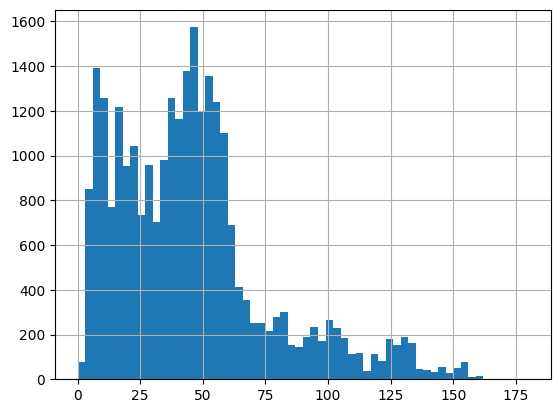

In [23]:
ROOT = Path(path)

def load(split):
    d = json.load(open(ROOT / split / "annotations_coco.json"))
    imgs = pd.DataFrame(d["images"]).rename(columns={"id": "image_id"})
    anns = pd.DataFrame(d["annotations"])
    n = anns[anns["iscrowd"] == 0].groupby("image_id").size()
    imgs["n_obj"] = imgs["image_id"].map(n).fillna(0).astype(int)
    imgs["split"] = split
    return imgs

frames = pd.concat([load("train"), load("val")], ignore_index=True)

print(frames.groupby("split")["n_obj"].describe(percentiles=[.5, .9, .99]).round(1))
print("кадрів без об'єктів:", (frames["n_obj"] == 0).sum())
print("кадрів з більше ніж 300 обʼєктів:", (frames["n_obj"] > 300).sum())

per_clip = (frames.groupby("video")["n_obj"]
            .agg(["mean", "median", "max"]).round(1).sort_values("median"))
print(per_clip.head(3))
print(per_clip.tail(3))

frames["n_obj"].clip(upper=400).hist(bins=60);

## Щільність об'єктів

**Що перевіряємо.** Скільки об'єктів припадає на один кадр і наскільки це відрізняється між кліпами.

**Що бачимо.**
- Train: у середньому ~46 об'єктів на кадр (1 105 516 об'єктів у 24 201 кадрі), медіана 43, p99 = 142, максимум 180.
- Val: у середньому ~40 (114 132 у 2 846), медіана 37, p99 ≈ 113, максимум 116.
- Кадрів без жодного об'єкта: 3 (усі в train, у val мінімум 8 об'єктів). Кадрів із понад 300 об'єктів: 0.
- Розкид між кліпами величезний: найрідший кліп має медіану 5 об'єктів на кадр, найщільніший 150, тобто різниця у ~30 разів.

**Висновки для подальших рішень.**
- Через 30-кратний розкид між кліпами середні метрики приховуватимуть поведінку на рідких і щільних сценах. Фолди будуємо по кліпах і стратифікуємо за щільністю, щоб кожен фолд мав і рідкі, і щільні кліпи. Метрики варто дивитися й окремо для щільних кліпів.

In [14]:
def trend(g):
    g = g.sort_values("frame_id")
    k = max(len(g) // 5, 1)
    return pd.Series({"first20": g["n_obj"].iloc[:k].mean(),
                      "last20": g["n_obj"].iloc[-k:].mean()})

t = frames.groupby("video").apply(trend)
t["ratio"] = t["last20"] / t["first20"].clip(lower=1)
print(t["ratio"].describe().round(2))

count    63.00
mean      1.05
std       0.40
min       0.39
25%       0.82
50%       0.99
75%       1.31
max       2.14
Name: ratio, dtype: float64


/tmp/ipykernel_2677/3125053814.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t = frames.groupby("video").apply(trend)


## Зміна щільності всередині кліпу

**Що перевіряємо.** Чи справді на початку кліпу об'єктів мало, а потім більше. Для кожного кліпу порівняли середню кількість об'єктів у перших 20% кадрів і в останніх 20% (ratio = останні / перші).

**Що бачимо.**
- Медіана ratio 0.99, середнє 1.05: у типовому кліпі щільність на початку й наприкінці однакова.
- Розкид від 0.39 до 2.14, середня половина кліпів лежить між 0.82 і 1.31. В окремих кліпах щільність помітно змінюється, але і вгору, і вниз.

**Висновки.**
- Гіпотеза "на початку мало, потім більше" не підтвердилась, загального тренду немає.
- Обрізати початки чи кінці кліпів немає підстав, а підсемплінг "кожен N-й кадр" не зсуває розподіл щільності.

In [21]:
# доказ: кожен ignore-регіон записаний 8 разів (по копії на клас)
crowd = anns[anns["iscrowd"] == 1]
print("різних класів на кадр з ignore:",
      crowd.groupby("key")["category_id"].nunique().value_counts().to_dict())

# робочі таблиці
objs = anns[anns["iscrowd"] == 0].copy()                                # звичайні об'єкти
ign = anns[(anns["iscrowd"] == 1) & (anns["category_id"] == 1)].copy()  # ignore, одна копія

print("об'єктів:", len(objs), "| ignore-регіонів без дублів:", len(ign))

різних класів на кадр з ignore: {8: 19524}
об'єктів: 1219648 | ignore-регіонів без дублів: 67838


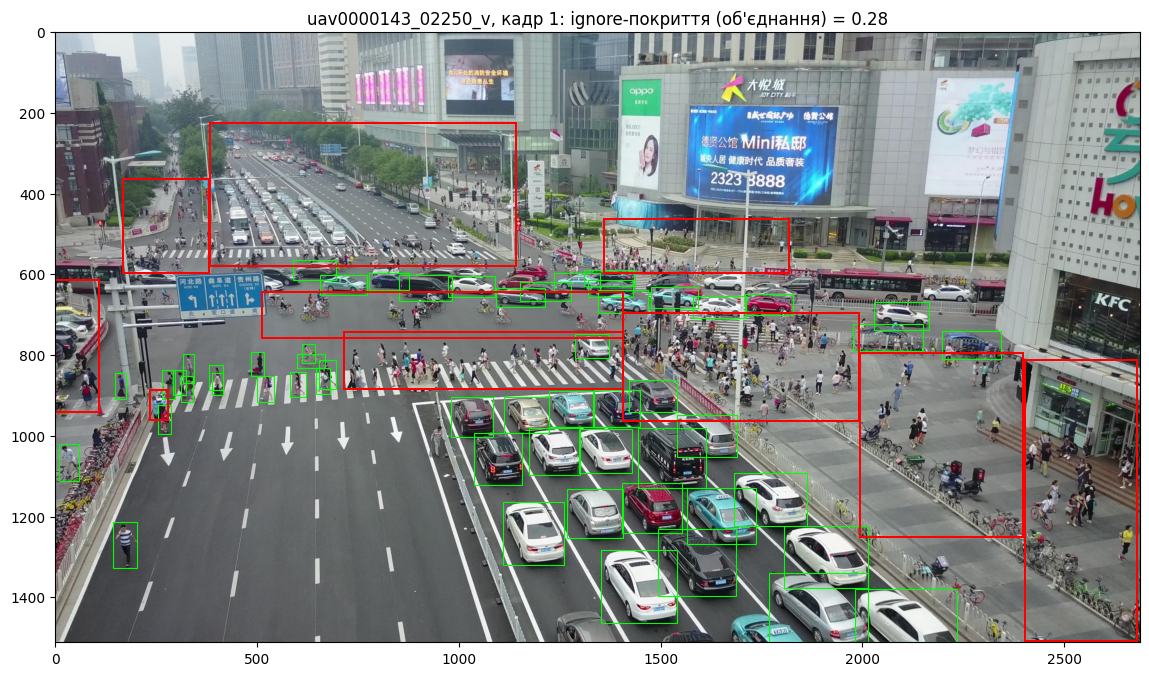

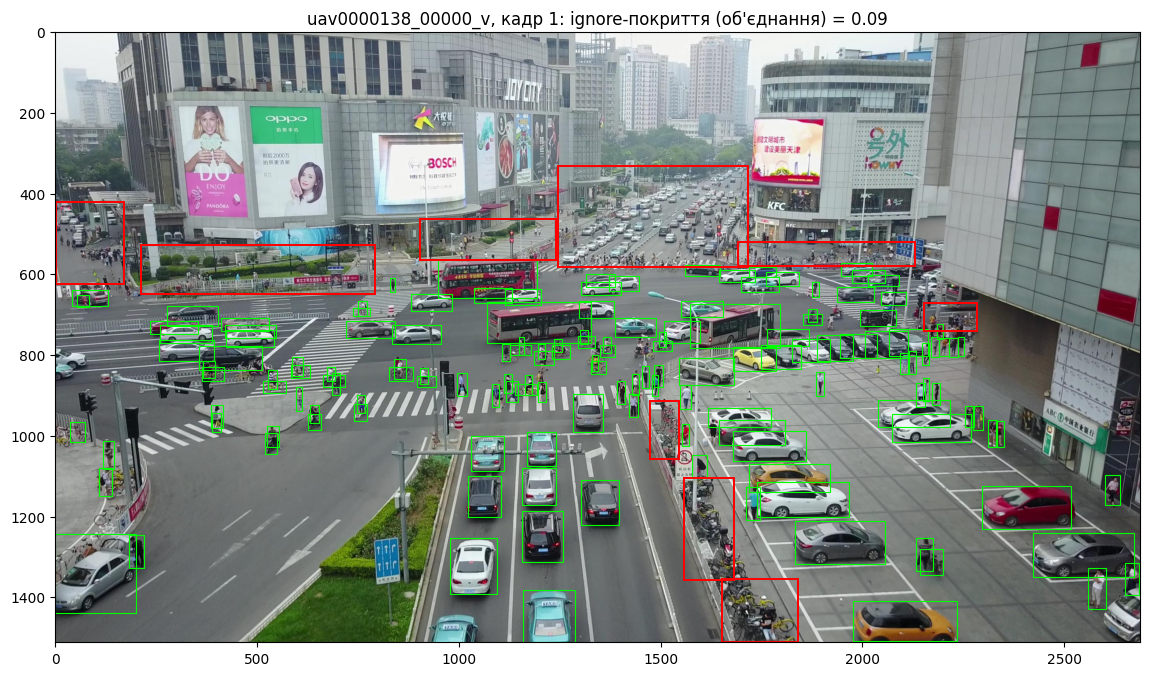

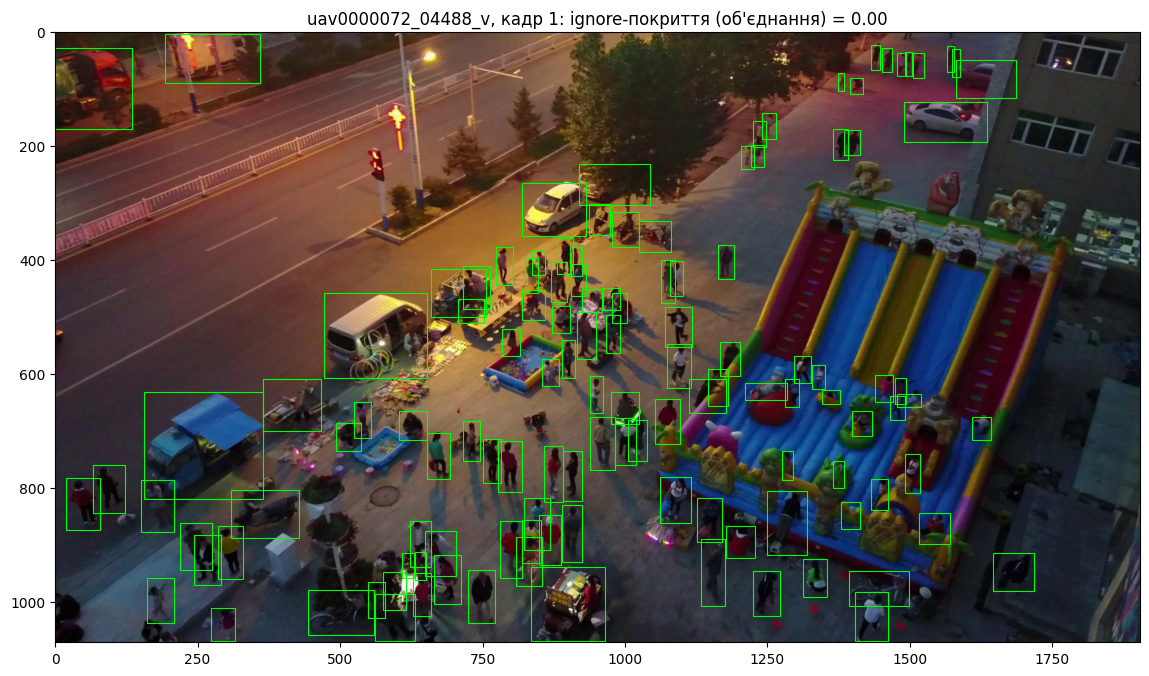

In [17]:
import numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

def show_frame(split, video, k=0):
    d = json.load(open(ROOT / split / "annotations_coco.json"))
    im = sorted([i for i in d["images"] if i["video"] == video],
                key=lambda i: i["frame_id"])[k]
    anns = [a for a in d["annotations"] if a["image_id"] == im["id"]]
    img = Image.open(ROOT / split / "images" / video / Path(im["file_name"]).name)

    mask = np.zeros((im["height"], im["width"]), bool)
    fig, ax = plt.subplots(figsize=(14, 8))
    ax.imshow(img)
    for a in anns:
        x, y, w, h = a["bbox"]
        crowd = a["iscrowd"] == 1
        if crowd:
            mask[int(y):int(y + h), int(x):int(x + w)] = True
        ax.add_patch(Rectangle((x, y), w, h, fill=False,
                               ec="red" if crowd else "lime", lw=1.2 if crowd else 0.8))
    ax.set_title(f"{video}, кадр {im['frame_id']}: ignore-покриття (об'єднання) = {mask.mean():.2f}")
    plt.show()

show_frame("train", "uav0000143_02250_v")
show_frame("train", "uav0000138_00000_v")   # найщільніший
show_frame("train", "uav0000072_04488_v")   # без ignore, для контрасту

In [22]:
ign["area"] = ign["w"] * ign["h"]
g = ign.groupby("key").agg(n_ign=("area", "size"), ign_area=("area", "sum"))
fr = imgs.merge(g, on="key", how="left").fillna({"n_ign": 0, "ign_area": 0})
fr["ign_frac"] = (fr["ign_area"] / (fr["width"] * fr["height"])).clip(upper=1)

print(fr.groupby("split").apply(lambda g: pd.Series({
    "кадрів з ignore, %": (g["n_ign"] > 0).mean() * 100,
    "регіонів на кадр (де є), медіана": g.loc[g["n_ign"] > 0, "n_ign"].median(),
    "частка площі (де є), медіана": g.loc[g["n_ign"] > 0, "ign_frac"].median(),
    "частка площі, p99": g["ign_frac"].quantile(.99),
    "кадрів з ign_frac > 0.3": (g["ign_frac"] > 0.3).sum(),
}), include_groups=False).round(3))

clip_stats = fr.groupby("video").agg(
    frames_with=("n_ign", lambda s: (s > 0).mean()),
    mean_frac=("ign_frac", "mean")).round(3)
print("кліпів без ignore:", (clip_stats["frames_with"] == 0).sum(), "з", len(clip_stats))
print(clip_stats.sort_values("mean_frac").iloc[[0, 1, 2, -3, -2, -1]])

       кадрів з ignore, %  регіонів на кадр (де є), медіана  \
split                                                         
train              74.749                               2.0   
val                50.387                               3.0   

       частка площі (де є), медіана  частка площі, p99  \
split                                                    
train                         0.016              0.196   
val                           0.014              0.100   

       кадрів з ign_frac > 0.3  
split                           
train                     84.0  
val                        0.0  
кліпів без ignore: 8 з 63
                    frames_with  mean_frac
video                                     
uav0000072_04488_v          0.0      0.000
uav0000076_00720_v          0.0      0.000
uav0000222_03150_v          0.0      0.000
uav0000295_02300_v          1.0      0.118
uav0000140_01590_v          1.0      0.165
uav0000143_02250_v          1.0      0.246


## Ignored regions

**Що перевіряємо.** Як ignored regions записані в даних, як часто трапляються, яку частину кадру займають і що саме закривають.

**Що бачимо.**
- У COCO-файлі кожен ignore-регіон записаний 8 разів (однаковий `bbox`, `category_id` від 1 до 8): у кожному з 19 524 кадрів з ignore рівно 8 класів. Далі працюємо з однією копією (67 838 регіонів без дублів). Для масок при тренуванні можна брати і `ignore/*.txt`, де регіон записаний один раз.
- Ignore є у 74.7% кадрів train і 50.4% кадрів val, у 8 із 63 кліпів їх немає зовсім.
- Їх небагато за кількістю й площею: де вони є, медіана 2 регіони на кадр у train і 3 у val, які займають ~1.6% і 1.4% кадру. p99 площі 19.6% у train і 10.0% у val.
- Великі покриття рідкісні й сконцентровані в train: 84 кадри мають понад 30% площі (≈0.3%), у val таких немає. Найбільше середнє покриття в кліпі 24.6% (`uav0000143_02250_v`).
- Площу рахували як суму площ регіонів. На перевіреному кліпі вона збігається з покриттям об'єднанням (0.284 проти 0.28), тож накладань практично немає.
- На візуалізації ignore це зони, де об'єкти надто дрібні чи щільні для поштучної розмітки (далека дорога, натовпи пішоходів і велосипедів), а великі об'єкти на передньому плані розмічені окремо. Покриття на першому кадрі трьох кліпів: 0.28, 0.09, 0.00.

**Висновки для подальших рішень.**
- Ignore є майже в кожному кадрі train, але займає мало, тож проблема не в обсязі. Проблема в тому, що в цих зонах об'єкти є, а розмітки немає: без маскування модель вчитиметься, що там фон.
- Кліпи з найбільшим ignore не виключаємо, у них багато розмічених об'єктів.
- В оцінці використовуємо `iscrowd=1`, щоб детекції в цих зонах не штрафувались. Спосіб маскування при тренуванні вибираємо окремо.
- У val немає кадрів із великим ignore, тож у цьому сенсі він "легший" за train.

In [24]:
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]

o = objs.merge(imgs[["key", "video", "width", "height"]], on="key")
o["size"] = (o["w"] * o["h"]) ** 0.5                      # sqrt(площі), пікселі оригіналу
o["cls"] = o["category_id"].map(lambda c: CLASSES[c - 1])
o["long_side"] = o[["width", "height"]].max(axis=1)

labels = ["<8", "8-16", "16-32", "32-96", ">96"]
o["bin"] = pd.cut(o["size"], [0, 8, 16, 32, 96, np.inf], labels=labels, right=False)

print("розмір в оригіналі, % об'єктів:")
print((o["bin"].value_counts(normalize=True).reindex(labels) * 100).round(1))
print("\nпо класах, %:")
print((pd.crosstab(o["cls"], o["bin"], normalize="index") * 100).round(1)[labels])

print("\nефективний розмір після ресайзу довгої сторони до imgsz:")
for s in (640, 960, 1280):
    eff = o["size"] * s / o["long_side"]
    print(f"imgsz={s}: <4px {(eff < 4).mean()*100:.1f}%, <8px {(eff < 8).mean()*100:.1f}%, <16px {(eff < 16).mean()*100:.1f}%")

розмір в оригіналі, % об'єктів:
bin
<8        0.0
8-16      2.0
16-32    22.4
32-96    64.1
>96      11.6
Name: proportion, dtype: float64

по класах, %:
bin        <8  8-16  16-32  32-96   >96
cls                                    
bicycle   0.0   2.8   18.8   75.6   2.8
bus       0.0   0.0    4.0   39.3  56.7
car       0.0   0.7   15.2   64.9  19.2
motor     0.0   4.1   27.3   66.8   1.7
person    0.0   3.8   33.8   61.7   0.7
tricycle  0.0   0.6   20.1   65.3  14.0
truck     0.0   0.0    9.1   57.5  33.4
van       0.0   0.2   19.2   63.8  16.7

ефективний розмір після ресайзу довгої сторони до imgsz:
imgsz=640: <4px 0.6%, <8px 9.7%, <16px 53.6%
imgsz=960: <4px 0.0%, <8px 1.8%, <16px 23.5%
imgsz=1280: <4px 0.0%, <8px 0.6%, <16px 9.7%


## Розміри об'єктів

**Що перевіряємо.** Розмір об'єкта як sqrt(w·h) у пікселях оригінального кадру, загалом і по класах, та ефективний розмір після ресайзу довгої сторони кадру до `imgsz`.

**Що бачимо.**
- В оригіналі: <8 px 0.0%, 8-16 px 2.0%, 16-32 px 22.4%, 32-96 px 64.1%, >96 px 11.6%. COCO-small (<32 px) це близько 24% об'єктів.
- Найдрібніші класи: person (~38% менших за 32 px) і motor (~31%). Bus і truck переважно великі (bus: 57% понад 96 px).
- Після ресайзу картина змінюється сильно. Частка об'єктів <16 px: 53.6% при imgsz=640, 23.5% при 960, 9.7% при 1280. Частка <8 px: 9.7%, 1.8%, 0.6%.

**Висновки для подальших рішень.**
- При imgsz=640 більше половини об'єктів стає меншими за 16 px, тож 640 імовірно надто мало. 960 зменшує цю частку більш ніж удвічі, 1280 додає менший виграш за вищу ціну. Гіпотезу перевіряємо експериментально (AP_small і час при 640 / 960 / 1280).
- Об'єктів у діапазоні 16-96 px близько 86%, це орієнтир для розмірів якорів у RetinaNet з урахуванням ресайзу.
- Розрахунок припускає пропорційний ресайз довгої сторони; розподіл роздільностей кадрів ще не перевірено.

In [25]:
res_tv = imgs.groupby(["width", "height"]).agg(clips=("video", "nunique"), frames=("key", "size"))
res_te = test_df.groupby(["width", "height"]).agg(clips=("clip", "nunique"), frames=("image_id", "size"))
print("train+val:\n", res_tv, "\n\ntest:\n", res_te)

cnt = o["cls"].value_counts()
print("\nкласи:\n", pd.DataFrame({"n": cnt, "%": (cnt / cnt.sum() * 100).round(1)}))

train+val:
               clips  frames
width height               
1344  756        13    6472
1360  765         1     962
1904  1071       32   13354
1920  1080        1     721
2688  1512       12    3738
2720  1530        3     822
3840  2160        1     978 

test:
               clips  frames
width height               
680   382         3     321
960   540         5     279
1344  756         7     441
1360  764        18    1474
1904  1072        4     305
1920  1080       11     991

класи:
                n     %
cls                   
car       537122  44.0
person    379013  31.1
motor     114844   9.4
van        53782   4.4
tricycle   46836   3.8
bicycle    46277   3.8
truck      31857   2.6
bus         9917   0.8


## Роздільності кадрів і класи

**Що бачимо.**
- Train+val: від 1344×756 до 3840×2160. Найчастіші 1904×1071 (32 кліпи) і 1344×756 (13 кліпів), 12 кліпів 2688×1512. Test: від 680×382 до 1920×1080, найбільше кліпів 1360×764 (18).
- 8 тестових кліпів (680×382 і 960×540, близько 16% кадрів) мають меншу роздільність, ніж будь-який кадр у train.
- Класи (кількість об'єктів): car 44.0%, person 31.1%, motor 9.4%, van 4.4%, tricycle 3.8%, bicycle 3.8%, truck 2.6%, bus 0.8%.

**Висновки.**
- Тренування й інференс мають працювати з однаковою роздільністю входу, а розбіжність роздільностей train і test потрібно врахувати (multi-scale аугментація) і перевірити на малих кліпах.
- Рідкі класи (bus, truck, bicycle, tricycle) важать для mAP так само, як car, тому їх AP потрібно дивитись окремо.

In [33]:
TARGET_IMG_SIZE = 960

objs_with_img = objs.merge(
    imgs[['image_id', 'split', 'width', 'height']],
    on=['image_id', 'split'],
    how='inner'
)

scale = TARGET_IMG_SIZE / objs_with_img[['width', 'height']].max(axis=1)
w_scaled = objs_with_img['w'] * scale
h_scaled = objs_with_img['h'] * scale

wh_samples = np.column_stack([w_scaled, h_scaled])
if len(wh_samples) > 100000:
    np.random.seed(42)
    sample_idx = np.random.choice(len(wh_samples), 100000, replace=False)
    wh_samples = wh_samples[sample_idx]

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10).fit(wh_samples)
anchors = kmeans.cluster_centers_
anchors = anchors[np.argsort(anchors[:, 0] * anchors[:, 1])]

print(f"Розраховані оптимальні розміри якорів (w, h) для imgsz={TARGET_IMG_SIZE}:")
for i, (w_a, h_a) in enumerate(anchors, 1):
    area_eq = np.sqrt(w_a * h_a)
    aspect_ratio = w_a / h_a
    print(f"Anchor {i}: {w_a:.1f} x {h_a:.1f} px | Еквівалентна сторона: {area_eq:.1f} px | Співвідношення w/h: {aspect_ratio:.2f}")

Розраховані оптимальні розміри якорів (w, h) для imgsz=960:
Anchor 1: 14.6 x 18.4 px | Еквівалентна сторона: 16.4 px | Співвідношення w/h: 0.79
Anchor 2: 30.7 x 29.6 px | Еквівалентна сторона: 30.2 px | Співвідношення w/h: 1.04
Anchor 3: 71.6 x 37.1 px | Еквівалентна сторона: 51.5 px | Співвідношення w/h: 1.93
Anchor 4: 43.3 x 63.6 px | Еквівалентна сторона: 52.5 px | Співвідношення w/h: 0.68
Anchor 5: 127.5 x 85.5 px | Еквівалентна сторона: 104.4 px | Співвідношення w/h: 1.49


In [36]:
areas = kmeans.cluster_centers_[:, 0] * kmeans.cluster_centers_[:, 1]
rank = np.empty(5, int)
rank[np.argsort(areas)] = np.arange(1, 6)

labels = rank[kmeans.predict(np.column_stack([w_scaled, h_scaled]))]
cls_names = objs_with_img["category_id"].map(lambda c: CLASSES[c - 1])
print((pd.crosstab(labels, cls_names, normalize="index") * 100).round(0))

category_id  bicycle   bus   car  motor  person  tricycle  truck  van
row_0                                                                
1                5.0   0.0  33.0   13.0    43.0       3.0    1.0  3.0
2                4.0   1.0  50.0    9.0    24.0       5.0    3.0  5.0
3                1.0   2.0  79.0    2.0     0.0       5.0    5.0  6.0
4                1.0   2.0  45.0    3.0    32.0       5.0    6.0  6.0
5                0.0  11.0  62.0    0.0     0.0       4.0   16.0  6.0


In [37]:
def best_iou(wh, anchors_wh):
    inter = (np.minimum(wh[:, None, 0], anchors_wh[None, :, 0]) *
             np.minimum(wh[:, None, 1], anchors_wh[None, :, 1]))
    union = (wh[:, None, 0] * wh[:, None, 1] +
             anchors_wh[None, :, 0] * anchors_wh[None, :, 1] - inter)
    return (inter / union).max(axis=1)

default = np.array([(s / r**0.5, s * r**0.5) for s in (32, 64, 128, 256, 512)
                    for r in (0.5, 1.0, 2.0)])

for name, a in (("стандартні", default), ("K-Means", anchors)):
    iou = best_iou(wh_samples, a)
    print(f"{name}: середній найкращий IoU {iou.mean():.2f}, частка < 0.5: {(iou < 0.5).mean()*100:.1f}%")

стандартні: середній найкращий IoU 0.48, частка < 0.5: 49.1%
K-Means: середній найкращий IoU 0.61, частка < 0.5: 20.7%


## Якорі: K-Means по (w, h)

- Центри кластерів (w × h, px): 14.6×18.4, 30.7×29.6, 71.6×37.1, 43.3×63.6, 127.5×85.5. Еквівалентна сторона 16, 30, 52, 52 і 104 px, співвідношення w/h: 0.79, 1.04, 1.93, 0.68, 1.49.
- Кластери відрізняються розміром і формою, а не класом: у кожному кластері є значна частка авто (від 33% до 79%).
- Найширший кластер (3, w/h 1.93) на 79% складається з авто й не містить пішоходів. Найменший (1) збагачений на пішоходів (43% проти 31% в усьому наборі), але теж містить 33% авто. Найбільший (5) збагачений на bus і truck (11% і 16% проти 0.8% і 2.6%), хоча 62% в ньому авто. Кластер 4 (високі боксі) змішаний: авто 45%, пішоходи 32%.
- Частка об'єктів, чий найкращий IoU із якорями нижчий за 0.5: стандартна сітка (15 якорів, розміри 32-512, співвідношення 0.5/1/2) 49.1% (середній найкращий IoU 0.48), K-Means (5 якорів) 20.7% (середній IoU 0.61).

**Висновки для подальших рішень.**
- Якорі задаємо за розміром і формою об'єктів, а не за класом.
- Стандартна сітка погано покриває наші дані: майже половина об'єктів не має якоря з IoU >= 0.5. Масштаби якорів зсуваємо під кластери (порядок 16-100 px при imgsz=960). Це оцінка лише за IoU: чи покращить вона детекцію, перевіряємо при тренуванні.
- Обмеження: кластеризація в просторі (w, h) із евклідовою відстанню, а не 1 − IoU, і k вибрано без перебору. Це вирішуємо на етапі RetinaNet, де якорі стануть параметром експерименту.

In [42]:
cl = (frames.groupby("video")
      .agg(split=("split", "first"), n_frames=("n_obj", "size"), dens=("n_obj", "median"))
      .reset_index())
cl["src"] = cl["video"].str.split("_").str[0]
cl["dens_bin"] = pd.qcut(cl["dens"], 3, labels=False)

N_FOLDS = 5
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
cl["fold"] = -1
for f, (_, idx) in enumerate(sgkf.split(cl, cl["dens_bin"], groups=cl["src"])):
    cl.loc[idx, "fold"] = f

assert cl.groupby("src")["fold"].nunique().max() == 1
print(cl.groupby("fold").agg(clips=("video", "size"), frames=("n_frames", "sum"),
                             dens=("dens", "mean")).round(1))
print(pd.crosstab(cl["fold"], cl["dens_bin"]))
cl.to_csv("folds.csv", index=False)

      clips  frames  dens
fold                     
0        13    5479  61.9
1        10    4843  65.8
2        15    5420  38.8
3        13    5783  50.4
4        12    5522  32.5
dens_bin  0  1  2
fold             
0         1  5  7
1         2  4  4
2         7  4  4
3         5  5  3
4         6  3  3


## Підготовка датасету для YOLO

Беремо готовий поділ на фолди (`cl` з блоку вище, або `folds.csv`) і збираємо папку для YOLO:
train = усі фолди крім `VAL_FOLD`, val = `VAL_FOLD`.
Ignore-зони замальовуємо сірим, але розмічені об'єкти всередині них не чіпаємо.
Кадри зменшуємо до `MAX_SIDE` по довгій стороні (мітки нормалізовані, тому не змінюються).
Тестові кадри не конвертуємо.

In [ ]:
import shutil
from concurrent.futures import ThreadPoolExecutor
import cv2

OUT = Path("/content/yolo_data")   # локальний диск Colab: швидкий, але стирається при перезапуску
VAL_FOLD = 0                       # який фолд іде у валідацію (0..4)
MAX_SIDE = 960                     # довга сторона після зменшення; менші кадри не збільшуємо
TRAIN_STEP = 2                     # кожен N-й кадр train (1 = усі кадри)
VAL_STEP = 1                       # кожен N-й кадр val
MASK_IGNORE = True                 # замалювати ignore-зони сірим
GRAY = 114

if "cl" not in globals():          # якщо блок з фолдами не запускали в цій сесії
    cl = pd.read_csv("folds.csv")

In [ ]:
# Індекс кадрів: по рядку на кадр зі шляхами до картинки, міток та ignore-файлу
def index_split(split):
    rows = []
    for clip_dir in sorted((ROOT / split / "images").iterdir()):
        for img in sorted(clip_dir.glob("*.jpg")):
            rows.append(dict(split=split, video=clip_dir.name, stem=img.stem, img=img,
                             lab=ROOT / split / "labels" / clip_dir.name / (img.stem + ".txt"),
                             ign=ROOT / split / "ignore" / clip_dir.name / (img.stem + ".txt")))
    return pd.DataFrame(rows)

fidx = pd.concat([index_split("train"), index_split("val")], ignore_index=True)
fidx = fidx.merge(cl[["video", "fold"]], on="video", how="left")
assert fidx["fold"].notna().all()

fidx["role"] = np.where(fidx["fold"] == VAL_FOLD, "val", "train")
fidx["k"] = fidx.groupby("video").cumcount()
step = np.where(fidx["role"] == "train", TRAIN_STEP, VAL_STEP)
sel = fidx[fidx["k"] % step == 0].copy()
print(sel.groupby("role").agg(кадрів=("stem", "size"), відео=("video", "nunique")))

In [ ]:
def read_boxes(path, w, h):
    # YOLO-рядки -> пікселі (x1, y1, x2, y2); беремо останні 4 числа, тож працює і для ignore без класу
    out = []
    if path.exists():
        for line in open(path):
            p = line.split()
            if len(p) < 4:
                continue
            cx, cy, bw, bh = map(float, p[-4:])
            out.append((max(int((cx - bw / 2) * w), 0), max(int((cy - bh / 2) * h), 0),
                        min(int((cx + bw / 2) * w) + 1, w), min(int((cy + bh / 2) * h) + 1, h)))
    return out

def convert(r):
    name = f"{r.video}__{r.stem}"
    dst_img = OUT / "images" / r.role / f"{name}.jpg"
    dst_lab = OUT / "labels" / r.role / f"{name}.txt"
    if dst_img.exists() and dst_lab.exists():
        return
    im = cv2.imread(str(r.img))
    h, w = im.shape[:2]
    if MASK_IGNORE and r.ign.exists():
        orig = im.copy()
        for x1, y1, x2, y2 in read_boxes(r.ign, w, h):
            im[y1:y2, x1:x2] = GRAY
        for x1, y1, x2, y2 in read_boxes(r.lab, w, h):   # розмічені об'єкти не затираємо
            im[y1:y2, x1:x2] = orig[y1:y2, x1:x2]
    s = MAX_SIDE / max(h, w)
    if s < 1:
        im = cv2.resize(im, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    cv2.imwrite(str(dst_img), im, [cv2.IMWRITE_JPEG_QUALITY, 95])
    if r.lab.exists():
        shutil.copy(r.lab, dst_lab)
    else:
        dst_lab.write_text("")

for role in ("train", "val"):
    (OUT / "images" / role).mkdir(parents=True, exist_ok=True)
    (OUT / "labels" / role).mkdir(parents=True, exist_ok=True)

rows = list(sel.itertuples(index=False))
with ThreadPoolExecutor(8) as ex:
    for i, _ in enumerate(ex.map(convert, rows)):
        if i % 2000 == 0:
            print(i, "/", len(rows))
print("готово")

In [ ]:
# data.yaml: де лежать train і val та назви класів (читає YOLO при тренуванні)
yaml_text = (f"path: {OUT}\ntrain: images/train\nval: images/val\nnames:\n"
             + "".join(f"  {i}: {n}\n" for i, n in enumerate(CLASSES)))
(OUT / "data.yaml").write_text(yaml_text)
print(yaml_text)

In [ ]:
# Перевірка: кожен кадр має мітки, класи 0..7, координати в [0, 1]
bad = 0
for role in ("train", "val"):
    imgs_out = sorted((OUT / "images" / role).glob("*.jpg"))
    for p in imgs_out:
        lab = OUT / "labels" / role / (p.stem + ".txt")
        assert lab.exists(), lab
        for line in open(lab):
            c, *xywh = line.split()
            if not (0 <= int(c) <= 7 and all(0 <= float(x) <= 1 for x in xywh)):
                bad += 1
    print(role, len(imgs_out), "кадрів")
print("некоректних рядків:", bad)

In [ ]:
# Візуальна перевірка: рамки мають стояти на об'єктах, ignore-зони бути сірими
def show(role, k=3, seed=0):
    rng = np.random.default_rng(seed)
    imgs_out = sorted((OUT / "images" / role).glob("*.jpg"))
    for p in rng.choice(imgs_out, k, replace=False):
        im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        h, w = im.shape[:2]
        for line in open(OUT / "labels" / role / (p.stem + ".txt")):
            c, cx, cy, bw, bh = line.split()
            cx, cy, bw, bh = float(cx) * w, float(cy) * h, float(bw) * w, float(bh) * h
            cv2.rectangle(im, (int(cx - bw / 2), int(cy - bh / 2)),
                          (int(cx + bw / 2), int(cy + bh / 2)), (0, 255, 0), 1)
        plt.figure(figsize=(14, 8)); plt.imshow(im); plt.title(p.name); plt.axis("off")

show("train")
show("val", k=1)

## Базова модель YOLO

Ultralytics, готові ваги COCO. Це baseline, з якого будемо порівнювати експерименти.
Метрика, яку YOLO друкує під час навчання, не знає про ignore-зони, тому остаточну оцінку рахуємо нижче через pycocotools.

In [ ]:
!pip -q install ultralytics
from ultralytics import YOLO

MODEL = "yolo11s.pt"
EPOCHS = 30
IMGSZ = MAX_SIDE      # навчаємо й прогнозуємо на тому ж розмірі, що й конвертували
SEED = 42

model = YOLO(MODEL)
model.train(data=str(OUT / "data.yaml"), epochs=EPOCHS, imgsz=IMGSZ, batch=16,
            seed=SEED, project="/content/runs", name="baseline", max_det=300, plots=False)

## Оцінка COCO mAP на валідаційному фолді

1. Збираємо еталон у форматі COCO лише для кадрів val-фолда, які ми конвертували.
   Ignore-зони лишаємо як `iscrowd=1` (у файлі вони записані по одній копії на клас, так і потрібно для оцінки по класах),
   тому pycocotools не штрафує детекції всередині них.
2. Прогноз робимо на конвертованих кадрах і повертаємо рамки в піксельні координати оригіналу.
3. Рахуємо mAP@[.5:.95], AP50, AP_small через `COCOeval`. Ліміт детекцій ставимо 500 на кадр, бо в сценах до 180 об'єктів стандартні 100 обрізали б recall.

In [ ]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

# Еталон COCO для кадрів val-фолда (id перенумеровуємо, бо в train і val вони перетинаються)
want = {(r.split, r.video, r.stem): f"{r.video}__{r.stem}.jpg"
        for r in sel[sel["role"] == "val"].itertuples()}
images_gt, anns_gt, new_id = [], [], {}
for split in ("train", "val"):
    d = json.load(open(ROOT / split / "annotations_coco.json"))
    for im in d["images"]:
        key = (split, im["video"], Path(im["file_name"]).stem)
        if key in want:
            new_id[(split, im["id"])] = len(images_gt) + 1
            images_gt.append(dict(id=len(images_gt) + 1, file_name=want[key],
                                  width=im["width"], height=im["height"]))
    for a in d["annotations"]:
        nid = new_id.get((split, a["image_id"]))
        if nid is not None:
            anns_gt.append(dict(id=len(anns_gt) + 1, image_id=nid, category_id=a["category_id"],
                                bbox=a["bbox"], iscrowd=a["iscrowd"],
                                area=a.get("area", a["bbox"][2] * a["bbox"][3])))

val_gt = dict(images=images_gt, annotations=anns_gt,
              categories=[dict(id=i + 1, name=n) for i, n in enumerate(CLASSES)])
json.dump(val_gt, open("val_gt_coco.json", "w"))
print(len(images_gt), "кадрів,", len(anns_gt), "анотацій,",
      sum(a["iscrowd"] for a in anns_gt), "з них ignore")
assert len(images_gt) == len(want)

In [ ]:
def predict_val(model, imgsz, conf=0.001, iou=0.6):
    # прогноз на конвертованих кадрах val; рамки переводимо в координати оригіналу
    gt_by_name = {im["file_name"]: im for im in val_gt["images"]}
    paths = sorted(str(p) for p in (OUT / "images" / "val").glob("*.jpg"))
    dets = []
    for r in model.predict(source=paths, imgsz=imgsz, conf=conf, iou=iou, max_det=500,
                           batch=16, stream=True, verbose=False):
        im = gt_by_name[Path(r.path).name]
        sx, sy = im["width"] / r.orig_shape[1], im["height"] / r.orig_shape[0]
        xyxy = r.boxes.xyxy.cpu().numpy()
        for (x1, y1, x2, y2), c, k in zip(xyxy, r.boxes.conf.cpu().numpy(), r.boxes.cls.cpu().numpy()):
            dets.append(dict(image_id=im["id"], category_id=int(k) + 1, score=float(c),
                             bbox=[float(x1 * sx), float(y1 * sy),
                                   float((x2 - x1) * sx), float((y2 - y1) * sy)]))
    return dets

def coco_eval(dets):
    gt = COCO("val_gt_coco.json")
    ev = COCOeval(gt, gt.loadRes(dets), "bbox")
    ev.params.maxDets = [1, 10, 500]
    ev.evaluate(); ev.accumulate(); ev.summarize()
    p = ev.eval["precision"][:, :, :, 0, -1]          # [IoU, recall, класи] для area=all
    per_class = {CLASSES[k]: float(np.mean(p[:, :, k][p[:, :, k] > -1])) for k in range(len(CLASSES))}
    s = ev.stats
    return dict(mAP=s[0], AP50=s[1], AP_small=s[3], AP_medium=s[4], AP_large=s[5]), per_class

In [ ]:
trained = YOLO("/content/runs/baseline/weights/best.pt")
dets = predict_val(trained, IMGSZ)
metrics, per_class = coco_eval(dets)
print({k: round(v, 4) for k, v in metrics.items()})
print({k: round(v, 3) for k, v in per_class.items()})

## Сабміт

Прогноз на оригінальних тестових кадрах, тож координати вже в пікселях оригіналу.
Формат: `class score x y w h` (клас з 0, (x, y) лівий верхній кут), до 500 боксів на кадр, порожній рядок для кадру без детекцій.

In [ ]:
def make_submission(model, imgsz, out_csv="submission.csv", conf=0.001, iou=0.6):
    paths = [str(ROOT / f) for f in test_df["file_name"]]
    pred = {}
    for img_id, r in zip(test_df["image_id"],
                         model.predict(source=paths, imgsz=imgsz, conf=conf, iou=iou, max_det=500,
                                       batch=8, stream=True, verbose=False)):
        parts = []
        for (x1, y1, x2, y2), c, k in zip(r.boxes.xyxy.cpu().numpy(),
                                          r.boxes.conf.cpu().numpy(), r.boxes.cls.cpu().numpy()):
            parts.append(f"{int(k)} {c:.4f} {x1:.1f} {y1:.1f} {x2 - x1:.1f} {y2 - y1:.1f}")
        pred[img_id] = " ".join(parts)

    sub = pd.read_csv(ROOT / "sample_submission.csv")
    sub["PredictionString"] = sub["image_id"].map(pred).fillna("")
    assert set(sub["image_id"]) == set(pred)       # кожен кадр sample_submission має прогноз
    sub.to_csv(out_csv, index=False)
    print(out_csv, sub.shape, "| порожніх рядків:", (sub["PredictionString"] == "").sum())
    return sub

sub = make_submission(trained, IMGSZ)